In [1]:
from google.colab import files
uploaded = files.upload()
csv_name = next (iter(uploaded))

Saving plant_health_dataset.csv to plant_health_dataset.csv


In [2]:
import pandas as pd

df = pd.read_csv(csv_name, keep_default_na=False)
display(df.head())
print('Records:', len(df))
print('Missing values by column:')
print(df.replace('', pd.NA).isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Target balance:')
print(df['plant_condition'].value_counts())

,leaf_color,spots,wilting,soil_moisture,growth_rate,plant_condition,suggested_response
0,Light Green,Many,None,15,Slow,Mild Stress,"Check watering, sunlight, and soil drainage"
1,Yellow,Many,Mild,34,Slow,Severe Stress,Provide urgent care and request grounds person...
2,Dark Green,Few,Mild,53,Normal,Healthy,Continue regular care and monitor weekly
3,Brown,Many,Severe,14,Slow,Severe Stress,Provide urgent care and request grounds person...
4,Yellow,Many,None,33,Slow,Diseased,"Inspect for disease, remove affected leaves, a..."


Records: 100
Missing values by column:
leaf_color            0
spots                 0
wilting               0
soil_moisture         0
growth_rate           0
plant_condition       0
suggested_response    0
dtype: int64
Duplicate rows: 0
Target balance:
plant_condition
Mild Stress      25
Severe Stress    25
Healthy          25
Diseased         25
Name: count, dtype: int64


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

features = ['leaf_color', 'spots', 'wilting', 'soil_moisture', 'growth_rate']
target = 'plant_condition'
X, y = df[features], df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')

def make_pipeline(classifier):
    categorical = ['leaf_color', 'spots', 'wilting', 'growth_rate']
    numeric = ['soil_moisture']
    preprocess = ColumnTransformer([
        ('category', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical),
        ('number', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric)
    ])
    return Pipeline([('preprocess', preprocess), ('classifier', classifier)])

Training rows: 75 | Test rows: 25


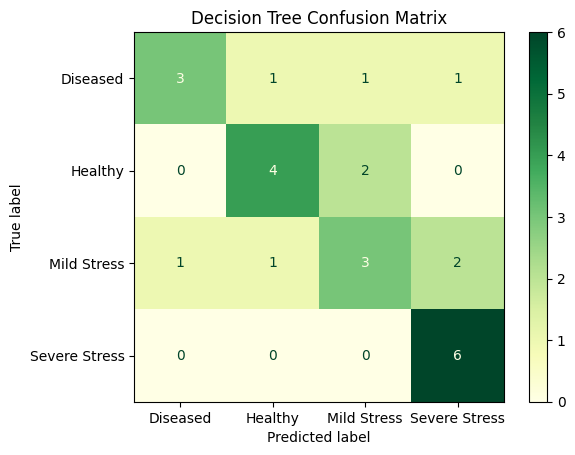

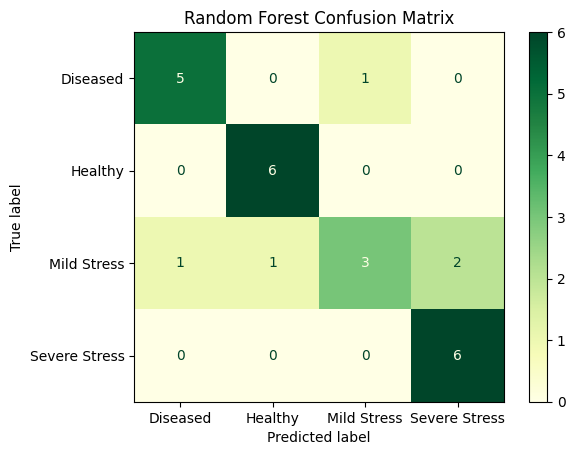

,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Decision Tree,0.64,0.640,0.64,0.625
Random Forest,0.80,0.796,0.80,0.780


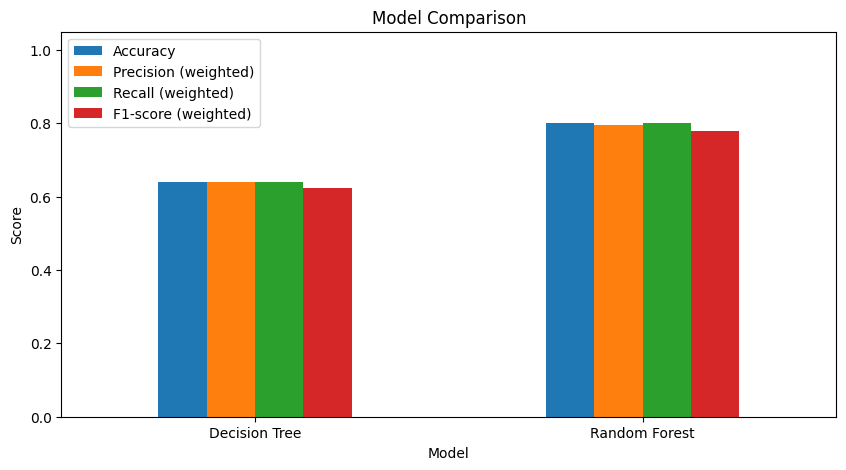

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=2, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=42)
}

fitted_models, results = {}, []
for name, classifier in models.items():
    pipeline = make_pipeline(classifier)
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    report = classification_report(y_test, predicted, output_dict=True, zero_division=0)
    fitted_models[name] = pipeline
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision (weighted)': report['weighted avg']['precision'],
        'Recall (weighted)': report['weighted avg']['recall'],
        'F1-score (weighted)': report['weighted avg']['f1-score']
    })
    ConfusionMatrixDisplay(confusion_matrix(y_test, predicted, labels=pipeline.classes_),
                           display_labels=pipeline.classes_).plot(cmap='YlGn')
    plt.title(f'{name} Confusion Matrix')
    plt.show()

comparison = pd.DataFrame(results).set_index('Model').round(3)
display(comparison)
comparison.plot(kind='bar', ylim=(0, 1.05), rot=0, figsize=(10, 5))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.show()

In [5]:
import joblib

best_name = comparison['F1-score (weighted)'].idxmax()
best_pipeline = fitted_models[best_name]
joblib.dump(best_pipeline, 'plant_health_pipeline.joblib')
comparison.to_csv('model_comparison.csv')

files.download('plant_health_pipeline.joblib')
files.download('model_comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>